# Staged production plan: frozen-transformer GFMC

**Draft dated 27 October 2026. Recommendation: qualify the direct-inference projector at 12 spins, establish feasibility and convergence at 48 spins, then grow the disorder average before adding larger sizes.**

The first production objective is a reliable disorder-averaged curve of $\langle q^2\rangle$ versus $\Gamma$, accompanied by equal-time connected correlations and explicit convergence evidence. A second objective is to establish whether the frozen guide reduces the computational cost of achieving a given accuracy. Finite-size phase analysis comes after these two objectives.

This notebook is a plan with locally executed evidence and workload calculations. All future run counts, thresholds and settings below are proposals. Numerical settings become production settings only after their qualification gates pass. Running this notebook reads local artifacts and performs small calculations.

**Completed baseline:** L=2, N=12, D=32, R=4; 7,168 population runs, 448 exact/guide caches, 448 finite-forward reference contexts. Final audit passed.

**Frozen checkpoint:** `shared_symmetric_alibi__L02-04-06-08__seed501__final.pt`  
SHA-256: `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`

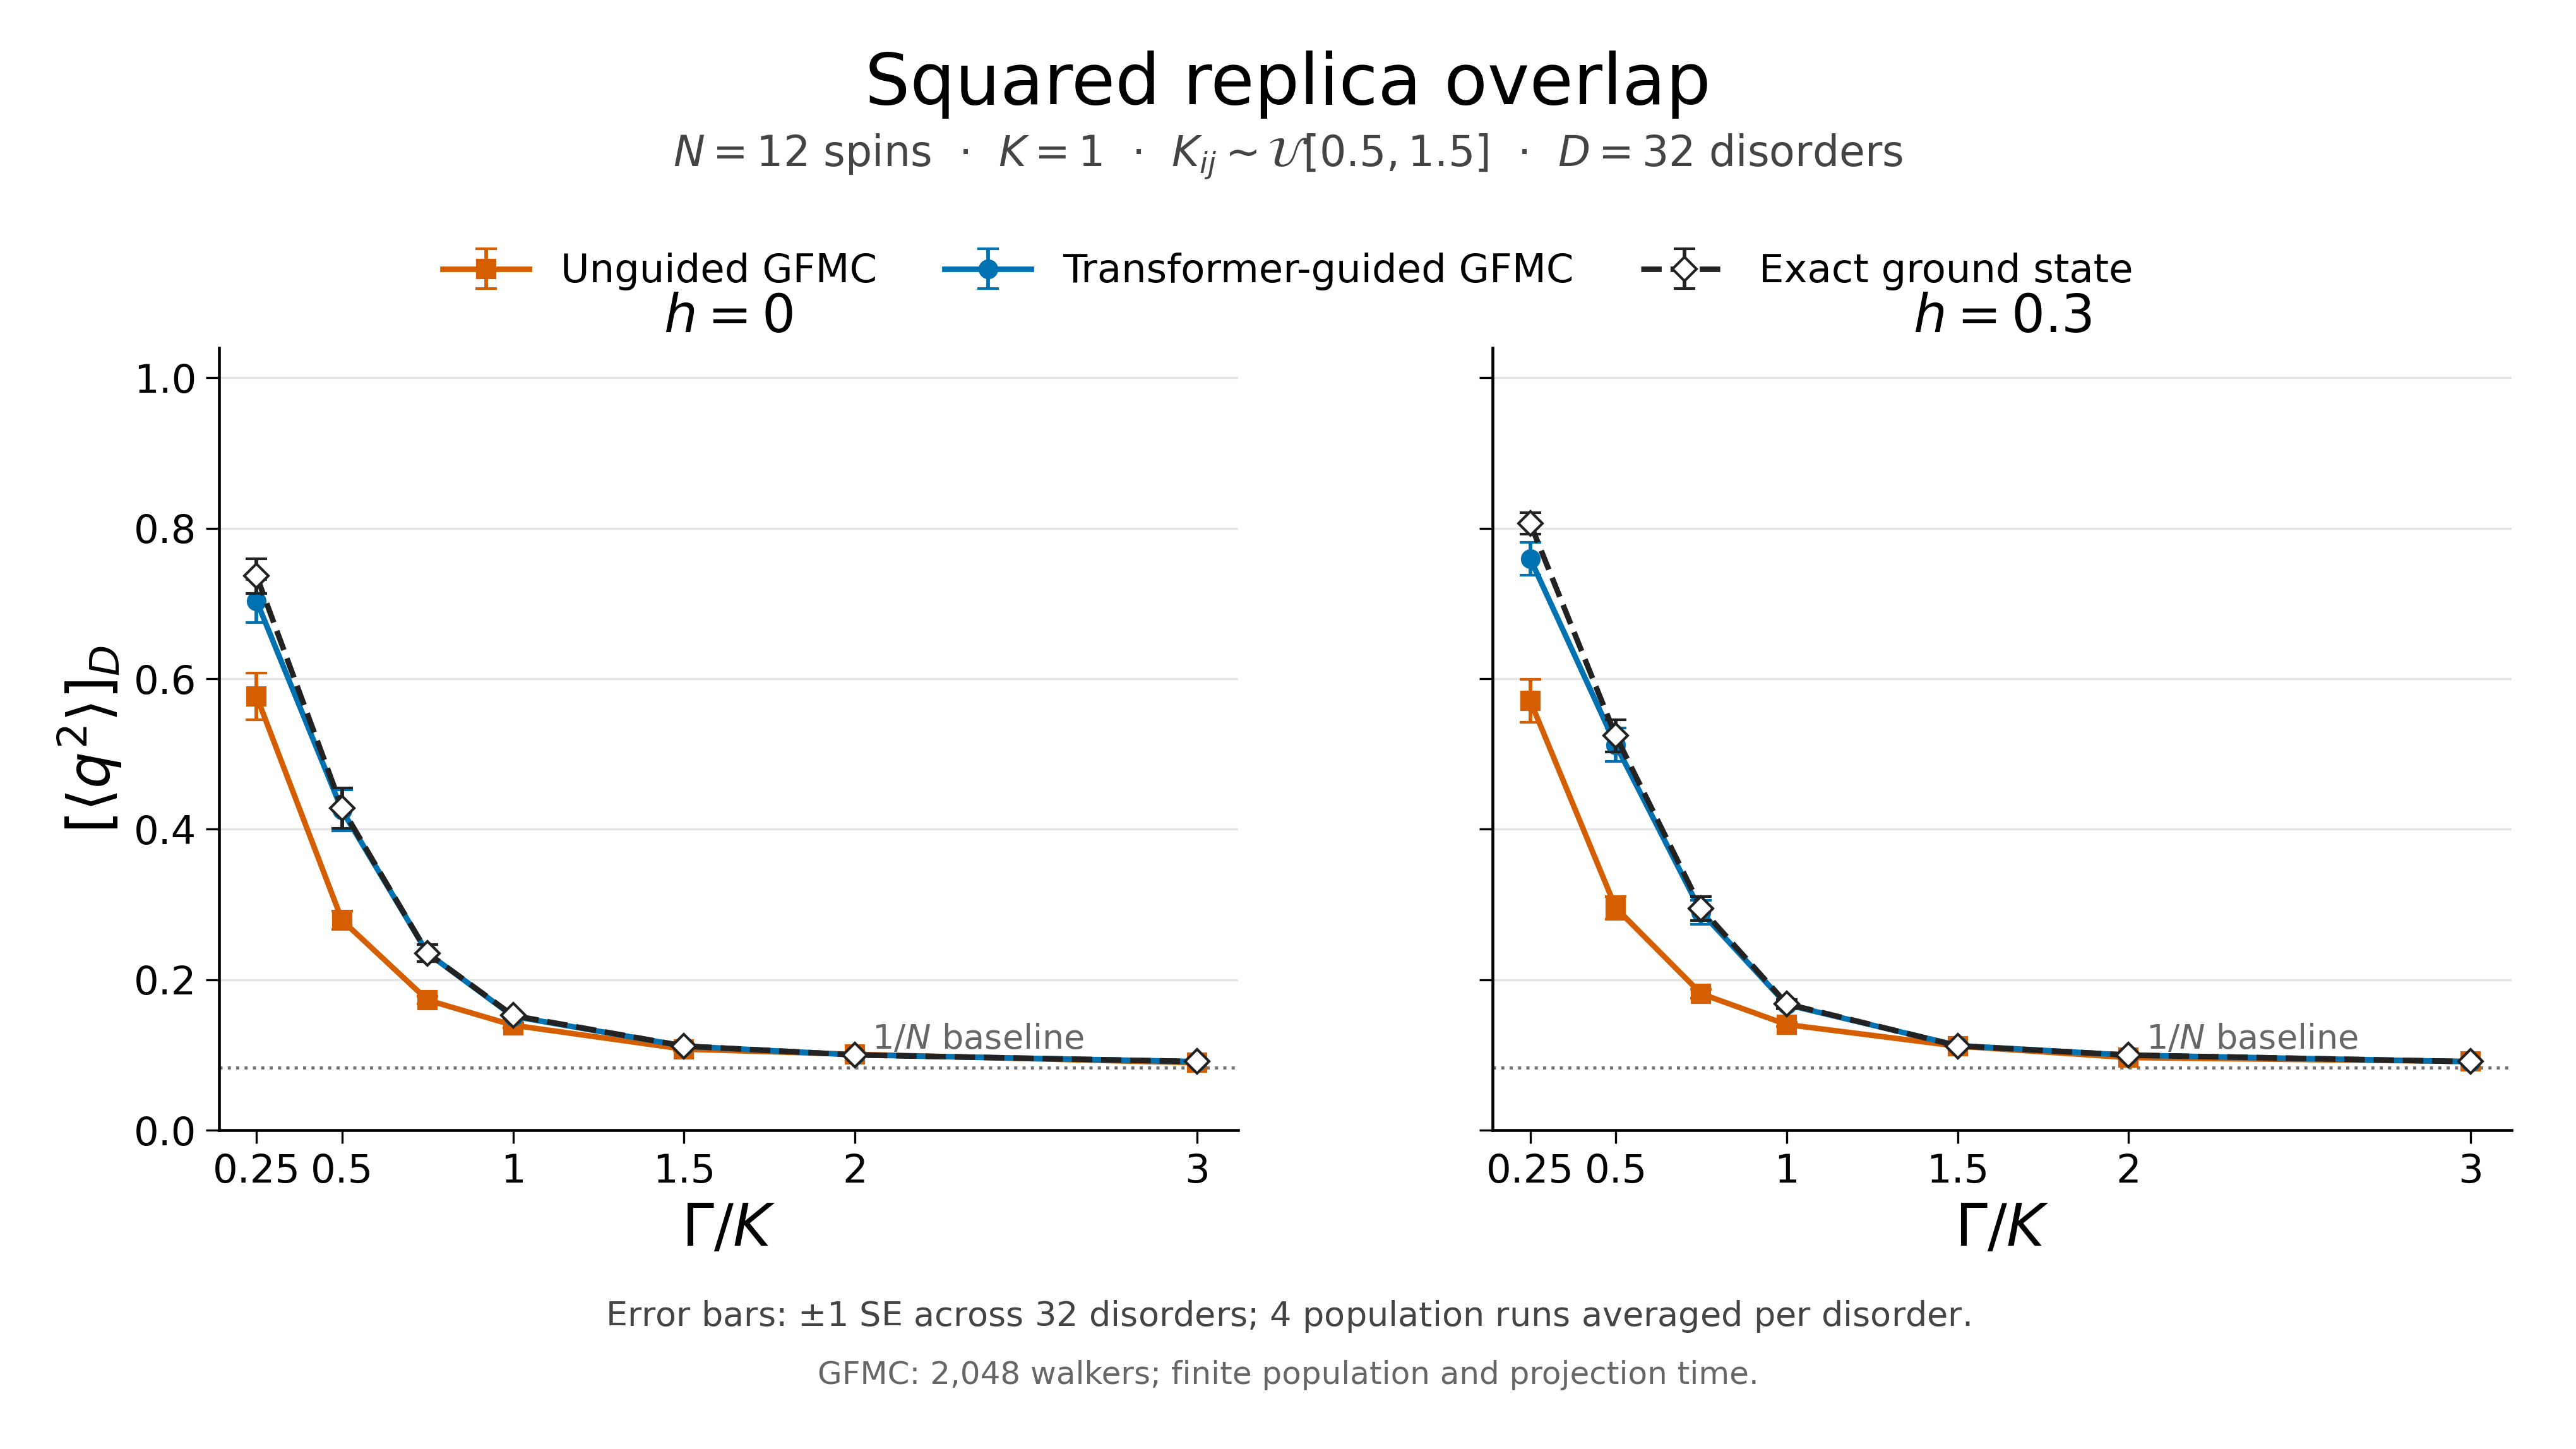

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

ROOT = Path('/Users/tianyiyan/Dropbox/spin-glasses')
RESULTS = ROOT / 'data/kagome/transformer_af_disorder_gfmc_v1'
manifest = json.loads((RESULTS / 'manifest.json').read_text())
audit = json.loads((RESULTS / 'audit.json').read_text())
assert audit['passed'] and audit['complete']
assert audit['checkpoint_sha256'] == manifest['checkpoint_sha256']
display(Markdown(
    f"**Completed baseline:** L={manifest['L']}, N={manifest['n_sites']}, "
    f"D={len(manifest['sample_ids'])}, R={len(manifest['seeds'])}; "
    f"{audit['populations']:,} population runs, {audit['caches']} exact/guide caches, "
    f"{audit['finite_forward']} finite-forward reference contexts. Final audit passed.\n\n"
    f"**Frozen checkpoint:** `{manifest['checkpoint_name']}`  \n"
    f"SHA-256: `{manifest['checkpoint_sha256']}`"
))
display(Image(filename=str(ROOT / 'figures/q2_vs_gamma.png'), width=1000))

## 1. What the completed study establishes

The 12-spin campaign covers $\Gamma/K=0.25,0.5,0.75,1,1.5,2,3$ and $h/K=0,0.3$, with 32 fresh disorders and four population repeats per point. It compares constant and frozen-transformer guides against exact ground states. The first eight disorders also have population, equilibration, forward-time and branching-cadence checks.

The guided $\langle q^2\rangle$ means closely follow the exact curve across much of the scan. The lowest-$\Gamma$ point retains a visible discrepancy. Larger populations gave the most consistent improvement; agreement in energy alone did not qualify the correlations. These findings motivate production work, but do not establish larger-size convergence.

At $h=0$, finite-size spin-flip symmetry forces our $q_{\mathrm{EA}}$ target to zero. The signed overlap estimator is sensitive to imperfect cancellation. Squared overlap is insensitive to independent global flips of the replicas; its improved agreement does not prove full sampling of the overlap distribution. Keep $q_{\mathrm{EA}}$ as a symmetry/sampling diagnostic.

The previous GFMC propagation used a complete lookup of the frozen network on the 12-spin Hilbert space. **That timing cannot be extrapolated to 48, 108 or 192 spins.** Existing direct-inference pilots establish that execution is possible; their short times and small populations do not qualify ground-state accuracy. Reuse their records for cost estimates only after checking their actual completion and configuration.

## 2. Fixed scientific specification

$$
H_J=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-\Gamma\sum_iX_i-h\sum_iZ_i,
\qquad K_{ij}\overset{\mathrm{iid}}{\sim}\mathcal U[0.5,1.5],\quad K=1.
$$

Use the kagome lattice with periodic boundaries and $N=3L^2$. Keep the bond width $w=0.5$ and both fields $h=0,0.3$ throughout the initial production campaign. Hold each bond realization fixed across $\Gamma$, methods, repeats and convergence settings. Identical sample IDs at different $L$ do not imply identical or nested bonds: the current disorder seed includes $L$.

Freeze the selected seed501 checkpoint recorded above. The main production claim concerns projection with this fixed guide. If retraining becomes necessary, make it a separate version, qualify it on development disorders, then freeze it before final evaluation. The earlier guide was trained at $L=2,4,6,8$; these sizes test performance on new disorders, not unseen-size generalization.

| Role | Observable | Interpretation |
|---|---|---|
| Primary | $Q_2(J)=\langle q^2\rangle_J=N^{-2}\sum_{ij}\langle Z_iZ_j\rangle_J^2$ | Overlap magnitude and pair correlations |
| Primary companion at $h>0$ | $\chi_{\mathrm{conn},J}=N^{-1}\sum_{ij}\mathcal C_{ij}^2$ | Correlations beyond field-induced polarization |
| Numerical check | $E_J/N$ | Mixed energy estimator; assess alongside correlation convergence |
| Sampling check | $\langle q\rangle_J=N^{-1}\sum_i\langle Z_i\rangle_J^2$ | Zero at finite $N$, $h=0$, $\Gamma>0$ |
| Later scaling diagnostics | $\langle q^4\rangle$, connected overlap structure factors | Qualify their moments and ancestry separately |

Here $q=N^{-1}\sum_i Z_i^{(a)}Z_i^{(b)}$ and $\mathcal C_{ij}=\langle Z_iZ_j\rangle_J-\langle Z_i\rangle_J\langle Z_j\rangle_J$. All susceptibilities in this plan are equal-time quantities. The baseline $1/N$ is the diagonal contribution to $Q_2$ and its value for independent unbiased spins; it is not a phase boundary. At $h>0$, $Q_2$ also contains polarization contributions.

Average per-disorder observables after forming replica moments. Use the existing four-replica forward-walking estimator for connected quantities, rather than squaring a noisy sample covariance. Retain every forward cycle and every disorder, including poor-ancestry cases.

## 3. Rollout and decision points

| Stage | Scope | Main question | Deliverable and gate |
|---|---|---|---|
| A — direct-path qualification | $L=2$, existing exact development benchmark | Does direct network inference reproduce the validated projector? | Exact-error, time/population and cache-invalidation checks pass |
| B — feasibility | $L=4$ ($N=48$), 4 development disorders, 3 $\Gamma$, both $h$ | Can direct GFMC support meaningful populations and projection times at an acceptable cost? | Measured throughput, memory, ancestry and a priced Stage C |
| C — convergence | $L=4$, 8 development disorders | Which parameters qualify $Q_2$ and connected correlations? | One-at-a-time escalation plus combined stress test meets prespecified tolerances |
| D — first production | $L=4$, 64 fresh disorders initially, full 7-point scan | Is the disorder average precise and stable? | Audited curves with statistical and systematic uncertainty; extend to 128/256 if justified |
| E — size expansion | $L=6$ ($N=108$), then $L=8$ ($N=192$) | Does the method remain feasible and converged as $N$ grows? | Repeat B/C at each size before allocating production disorders |
| F — scaling study | At least three qualified sizes, common field grid | Is there evidence of consistent finite-size behavior? | Scaling diagnostics with corrections, uncertainty and alternative explanations |

Advance on evidence, rather than a fixed calendar. A stage can yield a smaller validated domain: for example, publish converged moderate/high-$\Gamma$ results while low-$\Gamma$ points remain visibly unresolved. Predeclare this convergence-based rule and retain those unresolved points in the coverage report.

## 4. Stage A: qualify the scalable implementation

Use eight of the existing 12-spin benchmark disorders as development cases, all seven $\Gamma$ values and both fields. These already have exact references; do not recalculate those references unnecessarily.

1. Verify direct log amplitudes, all single-spin flip ratios, local energies and initialization probabilities against the frozen lookup for the same Hamiltonian. Exercise state-cache eviction and changes in $J$, $\Gamma$ and $h$. A cache must be scoped to the complete guide/context identity.
2. Compare constant-guide and direct-guide propagation on selected short cases. Use matched random streams where numerically practical; otherwise compare independent ensembles with uncertainty. Preserve four physical replicas per walker group and the same descendant weighting as the reference code.
3. Validate any throughput optimization at $L=2$ before applying it at larger $L$. Batching and exact memoization may change cost; reduced precision, clipped rates or modified resampling can change numerical behavior and need explicit checks.
4. On the hardest development points, extend the current ladder to $W=8192,32768$, $\tau_{\mathrm{eq}}=32,64,128$, and $\tau_{\mathrm{FW}}=8,16,32$ as needed. Change one parameter at a time, starting from the existing results; then test the chosen settings jointly. Start with four independent runs, adding repeats when the convergence comparison is too noisy to resolve.

**Gate A:** direct-versus-lookup numerical checks pass, the completed original audit remains reproducible, and correlation errors against exact are quantified under the proposed ladder. Persistent low-$\Gamma$ error triggers further diagnosis; it does not invalidate already qualified points. If new code changes the algorithm, create a new source snapshot and repeat the relevant checks.

## 5. Stage B: a bounded 48-spin feasibility pilot

Use four development disorders, $\Gamma=0.5,1,2$, $h=0,0.3$, both guides, and four independent population runs. Begin with $W=64$ four-replica walker groups, $\tau_{\mathrm{eq}}=2$, energy-measurement time $1$, $\tau_{\mathrm{FW}}=1$, four cycles and branch interval $0.1$. This is an execution/cost probe. Escalate representative contexts to $W=256$ and $1024$, plus longer projection, before extrapolating production cost. Benchmark $h=0$ separately because the symmetric guide requires extra network work.

Record elapsed time for initialization, direct network queries, propagation and reporting; GPU memory; unique/requested state queries; effective states/second; event counts; and ancestry versus forward time. Include both cold and warm cache behavior. Count $W$ as the number of four-replica groups, not the number of individual configurations.

Price the full algorithm, including guide inference and setup. Compare guided and unguided methods in two ways: identical populations/times to expose estimator behavior, and equal end-to-end compute to assess practical benefit. At $L=2$ use exact RMSE; at $L=4$ use precision and convergence evidence, explicitly acknowledging the absence of exact ground-state truth.

**Gate B:** the measured cost projects to a feasible Stage C within a recorded GPU-hour and memory budget, with room for repeats and failures. A production runner needs its own configuration, atomic outputs and budget cap; the existing hard-coded short-pilot runner is only a starting point. If $W\sim10^3$ and longer forward times are unaffordable, improve inference or projection before expanding disorders. A large count of short, collapsed runs cannot replace this gate.

## 6. Stage C: qualify populations, projection and ancestry at 48 spins

Use eight development disorders: four fixed in advance and four added by a documented difficult-case rule based on runtime/ancestry, not agreement with a desired curve. Start at $\Gamma=0.5,1,2$ and both fields. Include $\Gamma=0.25$ as a separate stress case before admitting it to the qualified scan. Check $0.75,1.5,3$ before applying an interpolated setting policy to them.

| Parameter | Candidate ladder | What it diagnoses |
|---|---|---|
| Walker groups $W$ | $512,2048,8192$; extend only if feasible | Population bias and loss of independent lineages |
| Equilibration $\tau_{\mathrm{eq}}$ | $16,32,64$ | Initial-state dependence and incomplete projection |
| Forward time $\tau_{\mathrm{FW}}$ | $4,8,16$ | Residual trial-state dependence of replica observables |
| Branch interval $\Delta\tau$ | $0.1,0.05$; add $0.025$ when needed | Finite-population sensitivity to resampling cadence |
| Forward cycles / repeats | $16,32$ cycles; $R=4$, then $8$ if needed | Statistical precision; cycles may be correlated |

These are candidate brackets, not certified values transferred from 12 spins. Start from the strongest feasible configuration suggested by B. Escalate each parameter separately, then combine the chosen larger population and longer times to detect interactions. Add checkpoints along a run where practical, preserving the same target definition.

Inspect mixed/growth energies, $Q_2$, $\chi_{\mathrm{conn}}/N$, overlap signs and initial-state dependence. Use guide-initialized runs and independent alternative initial states, with their initialization protocol recorded. At $h=0$, monitor the overlap distribution and spin-flip symmetry even if $Q_2$ looks stable. A symmetry-restoring move is a possible later algorithm change, requiring separate qualification.

Report descendant ESS, unique ancestors and largest-lineage fraction for **each** forward cycle and their distributions over disorders. As an initial alarm, any cycle with descendant ESS below 8 or a lineage fraction above 0.5 triggers review and a stronger run; these are failure alarms, not accuracy certificates. Never drop an unfavorable cycle to improve agreement. If longer forward time improves bias but collapses ancestry, increase population or change the separately validated algorithm.

## 7. Quantitative qualification and precision targets

Set the tolerances before evaluating the final disorders. The following are provisional absolute tolerances, in units $K=1$:

| Observable | Desired final disorder-average SE | Maximum unresolved numerical shift |
|---|---:|---:|
| $Q_2$ | $0.005$ | $0.002$ |
| $\chi_{\mathrm{conn}}/N$ | $0.005$ | $0.002$ |
| $E/N$ | $0.002$ | $0.001$ |

For each escalation form per-disorder differences between the stronger and candidate settings, averaging independent repeats within each disorder. Estimate the uncertainty of the mean difference using paired disorder resampling and independent-run variation. Pairing refers to the same Hamiltonian; random seeds do not make two different algorithms' trajectories identical.

An operational equivalence gate for observable $O$ is

$$
|\overline{\Delta O}|+1.96\,\operatorname{SE}(\overline{\Delta O})\leq\epsilon_O.
$$

Use this as a prespecified approximate 95% criterion, checking bootstrap intervals and repeat stability when the distribution is skewed. Require it for the final two relevant population/time levels and the combined stress test, at each qualified field context. If only two levels have been measured, add a third before claiming a plateau. If the interval is too wide, gather more repeats; an insignificant difference is not an equivalence result. Tolerance changes require a new documented target, never a silent relaxation after seeing results.

Check per-disorder absolute shifts and tails as well as their signed average, so opposite biases cannot cancel unnoticed. Broad confidence intervals from eight pilot disorders can require a larger qualification subset. At $L=2$, also compare directly to exact truth. At larger sizes this procedure establishes empirical stability over the tested range, not a rigorous upper bound on ground-state bias.

On the final sample, preselect at least eight audit disorders and repeat the stronger settings; expand that subset when numerical tails appear. Stronger runs on flagged disorders supplement this fixed subset. Report a separate systematic-sensitivity envelope, aiming for numerical uncertainty below half the achieved statistical SE. Tightening the statistical SE later can therefore require stronger numerical qualification.

## 8. Stage D: a fresh disorder average and defensible error bars

Once C passes, freeze the setting policy, source tree and checkpoint. Allocate a new development pool and final pool in a manifest after checking existing IDs. A suggested candidate allocation is IDs `60000:60032` for development and `61000:61256` for up to 256 final disorders; these ranges require a repository-wide collision/training-split check before reservation. Existing IDs `40000:40008` were reserved for another purpose and remain reserved.

Begin with the first 64 final disorders at $L=4$, four independent runs per point, the seven-point $\Gamma$ grid, both fields and the qualified settings. Prioritize completing all matched contexts for a disorder. Add disorders in prespecified blocks of 64, up to 256, if the target precision is unmet. This is a sequential precision policy; report each checkpoint and the stopping rule. Treat ordinary pointwise SE/intervals as descriptive under that stopping policy unless a sequentially valid procedure is implemented.

For the main large-system campaign, run the guided method throughout. Retain both guides on a fixed 16-disorder subset of the final pool for matched and equal-cost comparisons. Enlarge the baseline subset if the comparison is inconclusive. The code cell below also prices a full two-method design. Fix the subset before reading its results. Changes to the $\Gamma$ grid based on a pilot must be frozen before collecting the final pool; a later denser scan becomes a separately declared extension.

Generate an independent propagation RNG for each $(L,J,\Gamma,h,\mathrm{method},\mathrm{setting},r)$ using a stable, stored seed mapping. Keep disorder generation separate. The old campaign reused seed labels across contexts; its disorder bars condition on those streams. Fresh independent streams simplify the next campaign's uncertainty accounting.

For independent disorder and run streams,

$$
\widehat O_J=\frac1R\sum_{r=1}^{R}\widehat O_{J,r},\qquad
\overline O=\frac1D\sum_{J=1}^{D}\widehat O_J,\qquad
\widehat{\operatorname{SE}}(\overline O)=\frac{\operatorname{sd}_J(\widehat O_J)}{\sqrt D}.
$$

The last expression includes finite-run Monte Carlo scatter. Show a separate estimate of that contribution,

$$
\widehat{\operatorname{Var}}_{\mathrm{MC}}(\overline O)
=\frac{1}{D^2}\sum_{J=1}^{D}\frac{s_J^2}{R},
$$

where $s_J^2$ is the sample variance across the independent run means. Do not add this again to the disorder-level variance above. If estimating the intrinsic disorder variance, subtract the average within-disorder Monte Carlo variance with explicit finite-sample uncertainty. If MC dominates, buy more independent repeats or longer validated measurements; if disorder scatter dominates, buy more disorders.

Use paired disorder bootstrap intervals for method differences and derived ratios, retaining all $\Gamma$ points for a disorder together. Use independent run-level variance to assess MC contamination, avoiding naive nested resampling that counts it twice. Inspect distributions and leave-one-disorder-out sensitivity. Retain rare disorders at equal weight; rerun difficult cases to reduce uncertainty without selecting by observable value.

## 9. Workload and budget worksheet

The following counts are a planning envelope for one production setting per point. They exclude development ladders and the stronger final-sample audit. A population run contains four physical replicas per walker group. A low-$\Gamma$ point awaiting qualification remains a proposed run, not a certified result.

Use the feasibility pilot to measure end-to-end seconds per run separately by size, field, $\Gamma$ and method. For a serial GPU schedule,

$$
T_{\mathrm{GPU\ hours}}\approx\frac{1}{3600}\sum_{c\in\mathrm{contexts}}n_c\,t_c.
$$

Include guide loading/setup, convergence ladders, the final audit and retries. Initially reserve 30% contingency on top of measured estimates and display the underlying timing quantiles. If jobs share a GPU, measure aggregate throughput under that exact concurrency; summing overlapped wall times is not device-hours. The relative pilot cost is more useful than a calendar promise at this stage.

In [2]:
gammas = list(manifest['gamma'])
fields = list(manifest['h'])
repeats = 4
baseline_disorders = 16
lines = [
    '| Final disorders per size | Guided runs | Extra unguided runs (16 disorders) | Recommended total | Full two-method total |',
    '|---:|---:|---:|---:|---:|'
]
for disorders in (64, 128, 256):
    guided = disorders * len(gammas) * len(fields) * repeats
    baseline = baseline_disorders * len(gammas) * len(fields) * repeats
    lines.append(f'| {disorders} | {guided:,} | {baseline:,} | {guided+baseline:,} | {2*guided:,} |')
display(Markdown('\n'.join(lines)))

size_rows = ['| L | N | Uncorrelated baseline 1/N | Status in this plan |',
             '|---:|---:|---:|---|']
for L in (2, 4, 6, 8):
    sites = 3*L*L
    status = 'Completed exact benchmark' if L == 2 else (
        'First production target, conditional on gates' if L == 4 else 'Conditional expansion')
    size_rows.append(f'| {L} | {sites} | {1/sites:.6f} | {status} |')
display(Markdown('\n'.join(size_rows)))

# Fill from the Stage B/C timing records before scheduling production.
# Keys should identify L, h, Gamma and method; values are end-to-end seconds/run.
measured_seconds_per_run = {}
display(Markdown('**GPU-hour estimate pending:** larger-system production timings have not been inserted.'))

| Final disorders per size | Guided runs | Extra unguided runs (16 disorders) | Recommended total | Full two-method total |
|---:|---:|---:|---:|---:|
| 64 | 3,584 | 896 | 4,480 | 7,168 |
| 128 | 7,168 | 896 | 8,064 | 14,336 |
| 256 | 14,336 | 896 | 15,232 | 28,672 |

| L | N | Uncorrelated baseline 1/N | Status in this plan |
|---:|---:|---:|---|
| 2 | 12 | 0.083333 | Completed exact benchmark |
| 4 | 48 | 0.020833 | First production target, conditional on gates |
| 6 | 108 | 0.009259 | Conditional expansion |
| 8 | 192 | 0.005208 | Conditional expansion |

**GPU-hour estimate pending:** larger-system production timings have not been inserted.

## 10. Stage E/F: size expansion and physical conclusions

Move from $L=4$ to $6$ and then $8$, repeating the cost and convergence gates at each size. Keep the same disorder distribution, boundary conditions and field grid. New sizes may require more walkers, longer times or a different validated projector; do not carry settings over solely because the energy looks reasonable. If the frozen guide becomes too costly or inaccurate, finish the validated size/domain and develop a separately versioned improvement.

Plot $[Q_2]_D$ and $[\chi_{\mathrm{conn}}]_D$ against $\Gamma$ for each qualified size, showing each size's $1/N$ reference where useful. Add uncertainty on changes with size. The seven-point grid is a survey; any proposed transition region needs a prospectively declared denser grid and convergence checks there.

At $h=0$, one optional dimensionless diagnostic is

$$
g_L=\frac12\left(3-\frac{[\langle q^4\rangle]_D}{[\langle q^2\rangle]_D^2}\right).
$$

This is a ratio of disorder-averaged moments, not an average of per-disorder ratios. Record the convention and obtain its uncertainty by paired disorder resampling. Qualify fourth moments independently: they may require more samples than $Q_2$. Connected structure-factor ratios provide another candidate, after momentum and lattice conventions are checked. At nonzero field use a separately defined connected diagnostic; the uncentered Binder ratio includes polarization.

Finite-size crossings or a large $Q_2$ alone do not establish a spin-glass phase. Examine drift, finite-size corrections and possible conventional magnetic order using appropriate spin structure factors before making a glass interpretation. A thermodynamic $q_{\mathrm{EA}}$ claim also needs a stated symmetry-breaking/order-of-limits protocol, beyond the finite-size signed-overlap estimator used here.

## 11. Reproducible execution and release criteria

Each new campaign receives its own directory, immutable manifest and source snapshot. Record lattice/bonds or their verified seed reconstruction, checkpoint SHA-256, dependencies/device/precision, independent seed mapping, all projector settings, cache policy, per-run timings, convergence decisions and failed attempts. Resume only against the same identity; changed settings get new record keys. Write outputs atomically and preserve diagnostics and partial progress.

Keep development, qualification and final inference artifacts distinguishable. Store each independent run and its cycle-level estimates, ancestry and energy traces. Extend the current audit to cover the new sizes and direct path: it currently assumes the completed 12-spin campaign. Verify expected/actual coverage, duplicate keys, nonfinite data, provenance and disorder reconstruction before releasing plots. An executed notebook must distinguish planned, running, complete and qualified results.

Launch bounded compute batches with a recorded budget, checkpoint/mirror schedule and stop/resume behavior. A process cap stops dispatch and preserves the instance for resumption. Production timing and fair-use choices depend on the selected compute platform and are finalized after B.

**A production result is ready when:**

- The direct-path checks and provenance audit pass, and every published context has a documented qualification status.
- Population, time and cadence sensitivity satisfy the declared tolerances; poor-ancestry cases are resolved or remain explicitly unresolved.
- Final-disorder statistical precision meets the declared target, or a budget-limited precision is reported honestly; systematic sensitivity is shown separately.
- Matched-method comparisons distinguish fixed-settings behavior from equal-cost efficiency and include all inference/setup costs.
- Figures, tabulated data and the executed report can be regenerated from the frozen artifacts; missing or difficult disorders are visible in coverage.

## 12. Immediate next implementation batch

1. Inventory the existing local direct-pilot records and reserve new disorder/seed pools after a collision and training-split audit.
2. Add a configurable direct-inference campaign runner with four-replica estimator parity, stable seed mapping, timing/ancestry records, atomic resume and a process budget cap.
3. Complete Stage A checks for that runner and any inference optimizations.
4. Run the bounded Stage B 48-spin pilot, then populate the budget worksheet from measured records.
5. Freeze the Stage C qualification matrix and numerical tolerances; use its results to choose the first production settings and affordable disorder count.

The first milestone is therefore **a priced, validated 48-spin production configuration**, followed by a 64-disorder scan. Scaling to 108/192 spins follows only after this milestone is achieved.

### Local evidence and implementation references

- [Completed disorder study](disorder_averaged_guided_gfmc.ipynb)
- [Baseline specification and artifact layout](../code/transformer_qmc/DISORDER_GFMC.md)
- [Frozen-guide and earlier direct-pilot documentation](../code/transformer_qmc/FROZEN_SCAN_GFMC.md)
- [Direct-inference pilot](../code/transformer_qmc/direct_gfmc_pilot.py)
- [Continuous-time projector and replica tags](../code/transformer_qmc/projector.py)
- [Disorder generation and exact observable definitions](../code/transformer_qmc/physics.py)
- [Baseline manifest](../data/kagome/transformer_af_disorder_gfmc_v1/manifest.json)
- [Baseline audit](../data/kagome/transformer_af_disorder_gfmc_v1/audit.json)